# EDA 05 — German Credit (Statlog, UCI)

Nguồn: UCI Statlog German Credit (Hofmann, 1994), bản ARFF với nhãn thuộc tính dạng chữ.
1.000 người vay; nhãn gốc `class` (`bad` → 1) → `target`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "german_credit"
df = pd.read_csv(INTERIM / "german_credit.csv")
df.shape

(1000, 21)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,1000.0
features,20.0
numeric_features,7.0
categorical_features,13.0
duplicate_rows,0.0
cells_missing_pct,0.0
features_with_missing,0.0


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,1


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 1000, 'n_bad': 300, 'n_good': 700, 'bad_rate_pct': 30.0, 'imbalance_ratio': 2.33}


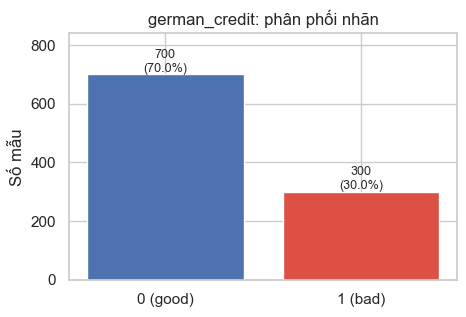

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

'Không có giá trị thiếu (NaN).'

'Không có cột nào đủ lượng thiếu để so sánh bad rate.'

## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
duration,33,4,18.0,72,1.093,0.909,7.0,0.0,0.629
age,53,19,33.0,75,1.019,0.587,2.3,0.0,0.571
credit_amount,921,250,2319.5,18424,1.947,4.265,7.2,0.0,0.555
installment_commitment,4,1,3.0,4,-0.531,-1.210,0.0,0.0,0.543
existing_credits,4,1,1.0,4,1.271,1.590,0.6,0.0,0.525
residence_since,4,1,3.0,4,-0.272,-1.381,0.0,0.0,0.502


Số cột số có |skew| > 2: 0 / 6


## 6. Phân phối theo nhãn

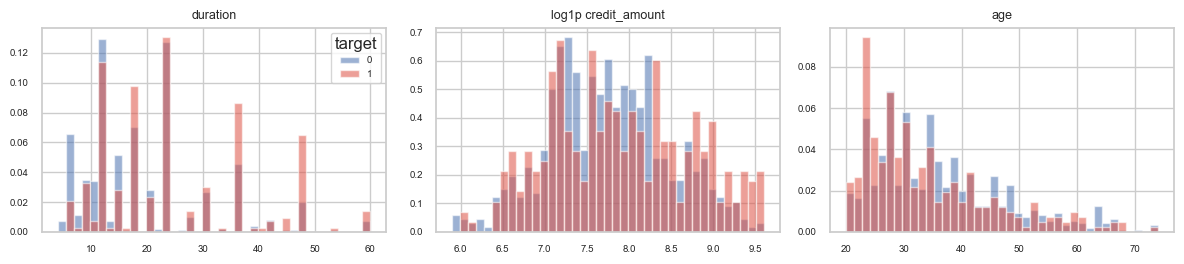

In [7]:
eda.plot_numeric_by_target(df, ["duration", "credit_amount", "age"], NAME, ncols=3, log=["credit_amount"])

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature            level                                                   
checking_status    0<=X<200                        269     39.03       26.9
                   <0                              274     49.27       27.4
                   >=200                            63     22.22        6.3
                   no checking                     394     11.68       39.4
credit_history     all paid                         49     57.14        4.9
                   critical/other existing credit  293     17.06       29.3
                   delayed previously               88     31.82        8.8
                   existing paid                   530     31.89       53.0
                   no credits/all paid              40     62.50        4.0
savings_status     100<=X<500                      103     33.01       10.3
                   500<=X<1000                      63     17.46        6.3
                   <100                            603     35.99       60.3
                   >=1000                           48     12.50        4.8
                   no known savings                183     17.49       18.3
purpose            business                         97     35.05        9.7
                   domestic appliance               12     33.33        1.2
                   education                        50     44.00        5.0
                   furniture/equipment             181     32.04       18.1
                   new car                         234     38.03       23.4
                   other                            12     41.67        1.2
                   radio/tv                        280     22.14       28.0
                   repairs                          22     36.36        2.2
                   retraining                        9     11.11        0.9
                   used car                        103     16.50       10.3
employment         1<=X<4                          339     30.68       33.9
                   4<=X<7                          174     22.41       17.4
                   <1                              172     40.70       17.2
                   >=7                             253     25.30       25.3
                   unemployed                       62     37.10        6.2
property_magnitude car                             332     30.72       33.2
                   life insurance                  232     30.60       23.2
                   no known property               154     43.51       15.4
                   real estate                     282     21.28       28.2
housing            for free                        108     40.74       10.8
                   own                             713     26.09       71.3
                   rent                            179     39.11       17.9
personal_status    female div/dep/mar              310     35.16       31.0
                   male div/sep                     50     40.00        5.0
                   male mar/wid                     92     27.17        9.2
                   male single                     548     26.64       54.8
foreign_worker     no                               37     10.81        3.7
                   yes                             963     30.74       96.3

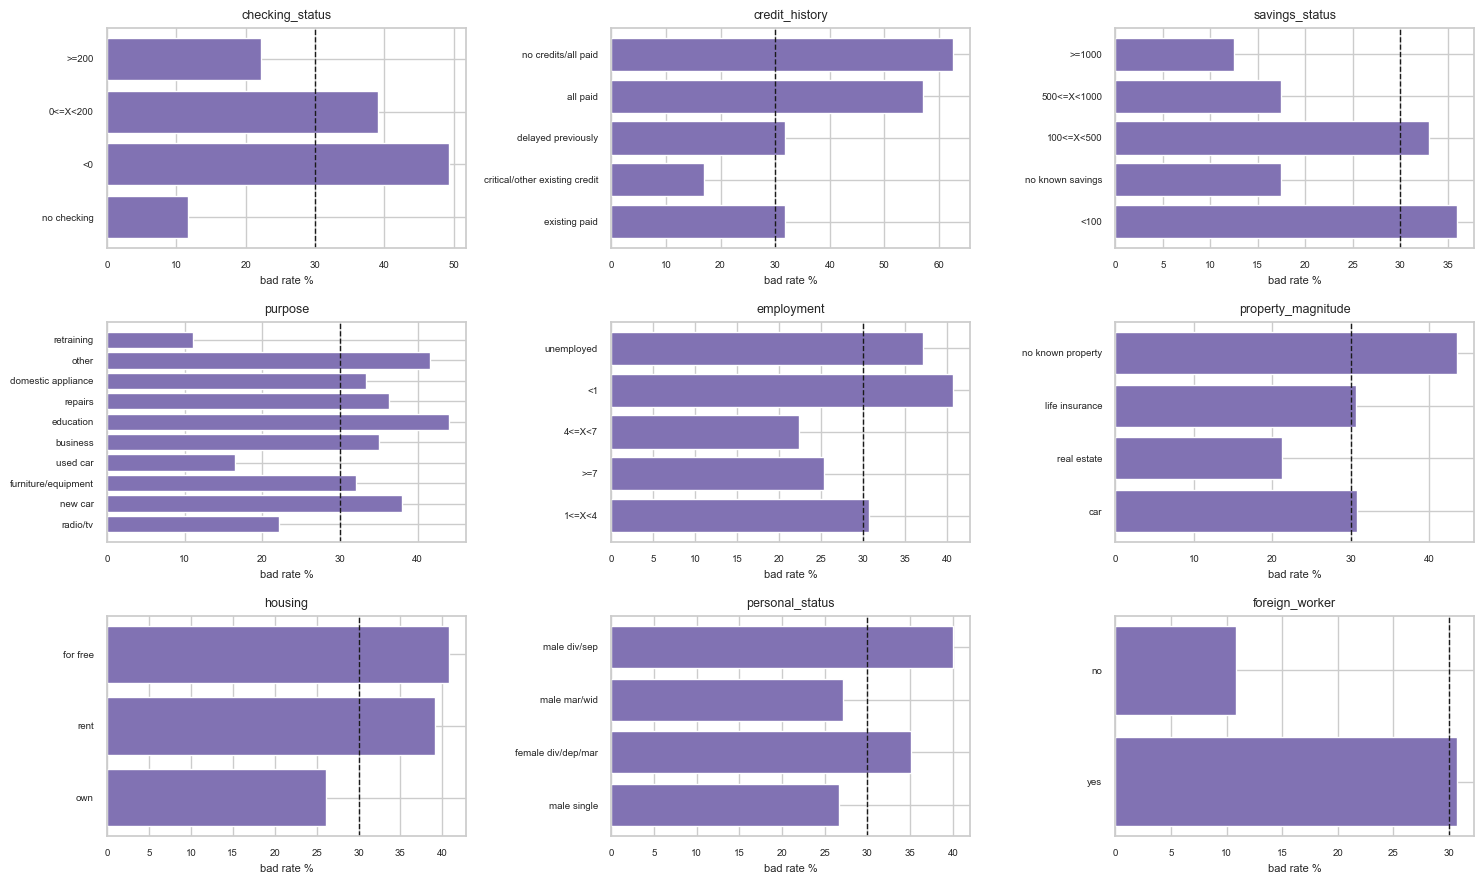

In [8]:
cats = ["checking_status", "credit_history", "savings_status", "purpose", "employment",
        "property_magnitude", "housing", "personal_status", "foreign_worker"]
display(eda.categorical_bad_rate(df, cats))
eda.plot_categorical_bad_rate(df, cats, NAME)

## 8. Tương quan

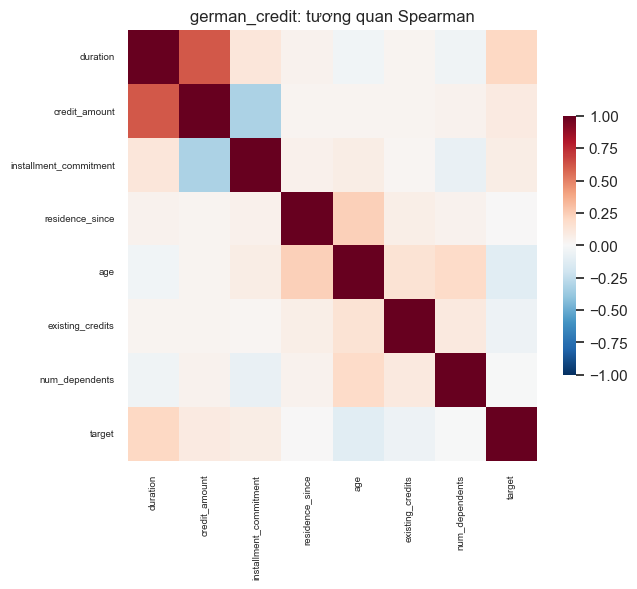

,a,b,spearman


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Nhóm nhỏ và quan hệ phản trực giác

In [10]:
g = df.groupby("credit_history")["target"].agg(["size", "mean"]).sort_values("mean")
display(g)
print("→ Nhóm 'critical/other existing credit' lại có bad rate THẤP NHẤT, còn 'no credits/all paid' CAO NHẤT.")
display(df.groupby("foreign_worker")["target"].agg(["size", "mean"]))

,size,mean
credit_history,,
critical/other existing credit,293,0.170648
delayed previously,88,0.318182
existing paid,530,0.318868
all paid,49,0.571429
no credits/all paid,40,0.625000


→ Nhóm 'critical/other existing credit' lại có bad rate THẤP NHẤT, còn 'no credits/all paid' CAO NHẤT.


,size,mean
foreign_worker,,
no,37,0.108108
yes,963,0.307373


## 10. Nhận xét

- **Nhãn:** bad rate = **30%** chính xác (300/700) — tỉ lệ cố định do *thiết kế lấy mẫu* (oversample người xấu), không phải tỉ lệ thực tế của ngân hàng (thực tế thấp hơn nhiều). Xác suất dự đoán cần hiệu chỉnh nếu dùng thực tế. Bộ dữ liệu cũng gắn với ma trận chi phí 5:1 (dự đoán nhầm bad→good đắt gấp 5).
- **Rất nhỏ (1.000 dòng)** và đa số biến là phân loại → kết quả đánh giá dao động mạnh giữa các lần chia; nhiều nhóm có < 50 mẫu.
- **Quan hệ phản trực giác / nghi lỗi mã hoá:** nhóm lịch sử tín dụng “critical account” có bad rate thấp nhất (~17%), còn “no credits / all paid” lại cao nhất (~62%). Grömping (2019) đã chỉ ra đây là lỗi mã hoá của bản Statlog (xem notebook South German Credit).
- Biến `foreign_worker` gần như hằng (96% “yes”).
- Không có missing, không trùng lặp; biến số ít lệch (skew ≤ 2).

In [11]:
EXTRA = {}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})